# SARIMA and SARIMAX for Time Series Forecasting

This notebook demonstrates seasonal statistical forecasting with **SARIMA** and **SARIMAX** using `statsmodels`.

### Learning objectives
- Understand the seasonal ARIMA model and its notation.
- Create and inspect a monthly demand series with annual seasonality.
- Split data chronologically into train, validation, and test sets.
- Fit and evaluate a SARIMA model.
- Add external regressors and fit a SARIMAX model.
- Compare forecasts using MAE, RMSE, WMAPE, and bias.
- Inspect residuals and produce future forecasts with prediction intervals.

**Important:** The data is synthetic and designed for learning. In a real forecasting project, choose orders and seasonal periods using domain knowledge, validation performance, diagnostics, and operational constraints.

## 1. Install and import libraries

Install dependencies if needed:

```bash
pip install numpy pandas matplotlib seaborn statsmodels scikit-learn
```

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

from sklearn.metrics import mean_absolute_error, mean_squared_error

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Generate a synthetic monthly demand dataset

The example represents monthly demand for a product family. It contains:
- A gradual upward trend.
- Annual seasonality (period = 12 months).
- Random noise.
- Promotion activity.
- A price index.
- A temperature-like external variable.

Promotion and price are included as potential explanatory variables for SARIMAX. In practice, use regressors only when they are relevant and their values are known or can be forecast for the prediction horizon.

In [2]:
dates = pd.date_range(start="2015-01-01", periods=120, freq="MS")
t = np.arange(len(dates))
month = dates.month

# Seasonal demand pattern: stronger demand in selected months
seasonal_pattern = np.array([0, -8, -5, 2, 8, 14, 18, 12, 5, -2, 10, 22])
seasonality = seasonal_pattern[month - 1]

# External variables
promotion = np.random.binomial(1, 0.22, size=len(dates))
price_index = 100 + 0.025 * t + np.random.normal(0, 1.5, len(dates))
temperature = 22 + 8 * np.sin(2 * np.pi * (month - 3) / 12) + np.random.normal(0, 1.2, len(dates))

# Demand responds positively to promotion and negatively to price
noise = np.random.normal(0, 7, len(dates))
demand = (
    180
    + 0.65 * t
    + seasonality
    + 24 * promotion
    - 1.1 * (price_index - 100)
    + 0.7 * (temperature - 22)
    + noise
)

df = pd.DataFrame({
    "date": dates,
    "demand": demand,
    "promotion": promotion,
    "price_index": price_index,
    "temperature": temperature
}).set_index("date")

df.head()

,demand,promotion,price_index,temperature
date,,,,
2015-01-01,177.640639,0,98.946920,16.216599
2015-02-01,190.170179,1,99.533507,18.781670
2015-03-01,183.452990,0,99.461838,21.621677
2015-04-01,188.690432,0,97.879728,26.910763
2015-05-01,188.423490,0,100.544180,28.000813


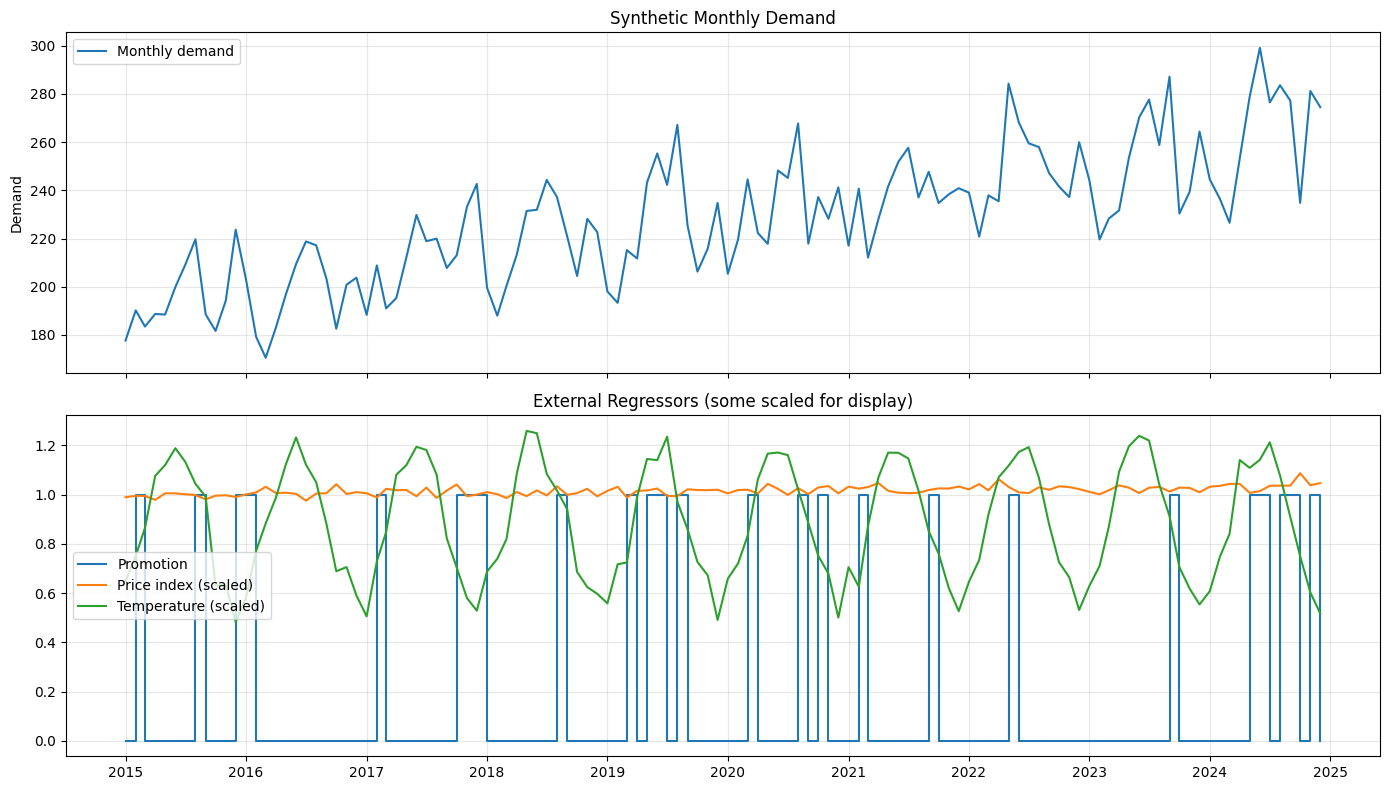

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(df.index, df["demand"], label="Monthly demand")
axes[0].set_title("Synthetic Monthly Demand")
axes[0].set_ylabel("Demand")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(df.index, df["promotion"], label="Promotion", drawstyle="steps-post")
axes[1].plot(df.index, df["price_index"] / 100, label="Price index (scaled)")
axes[1].plot(df.index, df["temperature"] / 25, label="Temperature (scaled)")
axes[1].set_title("External Regressors (some scaled for display)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Understand the seasonal structure

For monthly data with an annual pattern, the seasonal period is usually `s = 12`. For quarterly data, it is often `s = 4`; for weekly data with a yearly pattern, it may be around `s = 52` (depending on the calendar and data definition).

A seasonal pattern can be inspected by comparing observations 12 months apart. A seasonal plot is a useful visual check, but it does not by itself determine the model order.

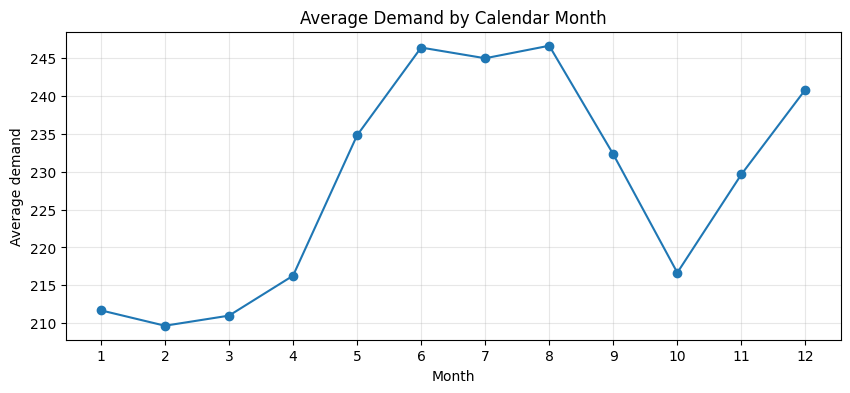

In [4]:
monthly_profile = df.groupby(df.index.month)["demand"].mean()

plt.figure(figsize=(10, 4))
plt.plot(monthly_profile.index, monthly_profile.values, marker="o")
plt.xticks(range(1, 13))
plt.xlabel("Month")
plt.ylabel("Average demand")
plt.title("Average Demand by Calendar Month")
plt.grid(True, alpha=0.3)
plt.show()

## 4. Train, validation, and test split

Do not randomly shuffle time-series observations. We preserve time order:

- First 70%: training data, used to estimate model parameters.
- Next 15%: validation data, used to compare candidate models.
- Final 15%: test data, held out for a final unbiased evaluation.

The exact proportions are not universal. For short series, rolling-origin time-series cross-validation may be more reliable than a single split.

In [5]:
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = df.iloc[:train_end].copy()
validation = df.iloc[train_end:val_end].copy()
test = df.iloc[val_end:].copy()

y_train = train["demand"]
y_val = validation["demand"]
y_test = test["demand"]

print(f"Train:      {train.index.min().date()} to {train.index.max().date()} ({len(train)} rows)")
print(f"Validation: {validation.index.min().date()} to {validation.index.max().date()} ({len(validation)} rows)")
print(f"Test:       {test.index.min().date()} to {test.index.max().date()} ({len(test)} rows)")

Train:      2015-01-01 to 2021-12-01 (84 rows)
Validation: 2022-01-01 to 2023-06-01 (18 rows)
Test:       2023-07-01 to 2024-12-01 (18 rows)


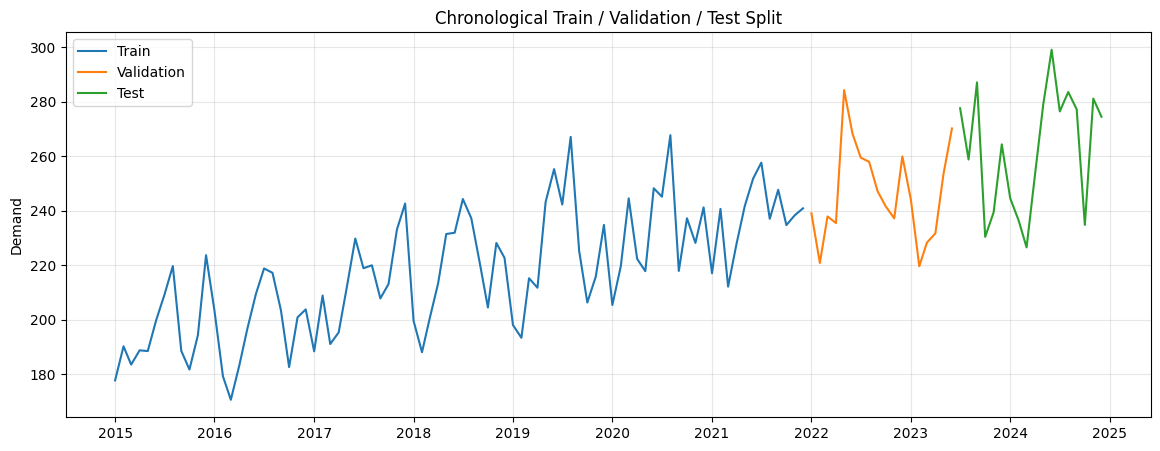

In [6]:
plt.figure(figsize=(14, 5))
plt.plot(y_train, label="Train")
plt.plot(y_val, label="Validation")
plt.plot(y_test, label="Test")
plt.title("Chronological Train / Validation / Test Split")
plt.ylabel("Demand")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 5. Stationarity and differencing

SARIMA is written as:

`SARIMA(p, d, q) × (P, D, Q, s)`

- `p`: non-seasonal autoregressive order.
- `d`: non-seasonal differencing order.
- `q`: non-seasonal moving-average order.
- `P`: seasonal autoregressive order.
- `D`: seasonal differencing order.
- `Q`: seasonal moving-average order.
- `s`: seasonal period.

Non-seasonal differencing can remove a changing level or trend. Seasonal differencing compares an observation with the value one full seasonal cycle earlier:

`y'_t = y_t - y_(t-s)`

For monthly annual seasonality, `s = 12`.

The Augmented Dickey-Fuller (ADF) test has a unit-root null hypothesis. A small p-value provides evidence against a unit root, but stationarity decisions should also consider plots, domain knowledge, and model diagnostics.

In [7]:
adf_result = adfuller(y_train.dropna())

print("ADF statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 4))
print("Critical values:", adf_result[4])

if adf_result[1] < 0.05:
    print("At 5% significance, reject the unit-root null hypothesis.")
else:
    print("At 5% significance, do not reject the unit-root null hypothesis.")

ADF statistic: -0.3295
p-value: 0.9212
Critical values: {'1%': np.float64(-3.524624466842421), '5%': np.float64(-2.9026070739026064), '10%': np.float64(-2.5886785262345677)}
At 5% significance, do not reject the unit-root null hypothesis.


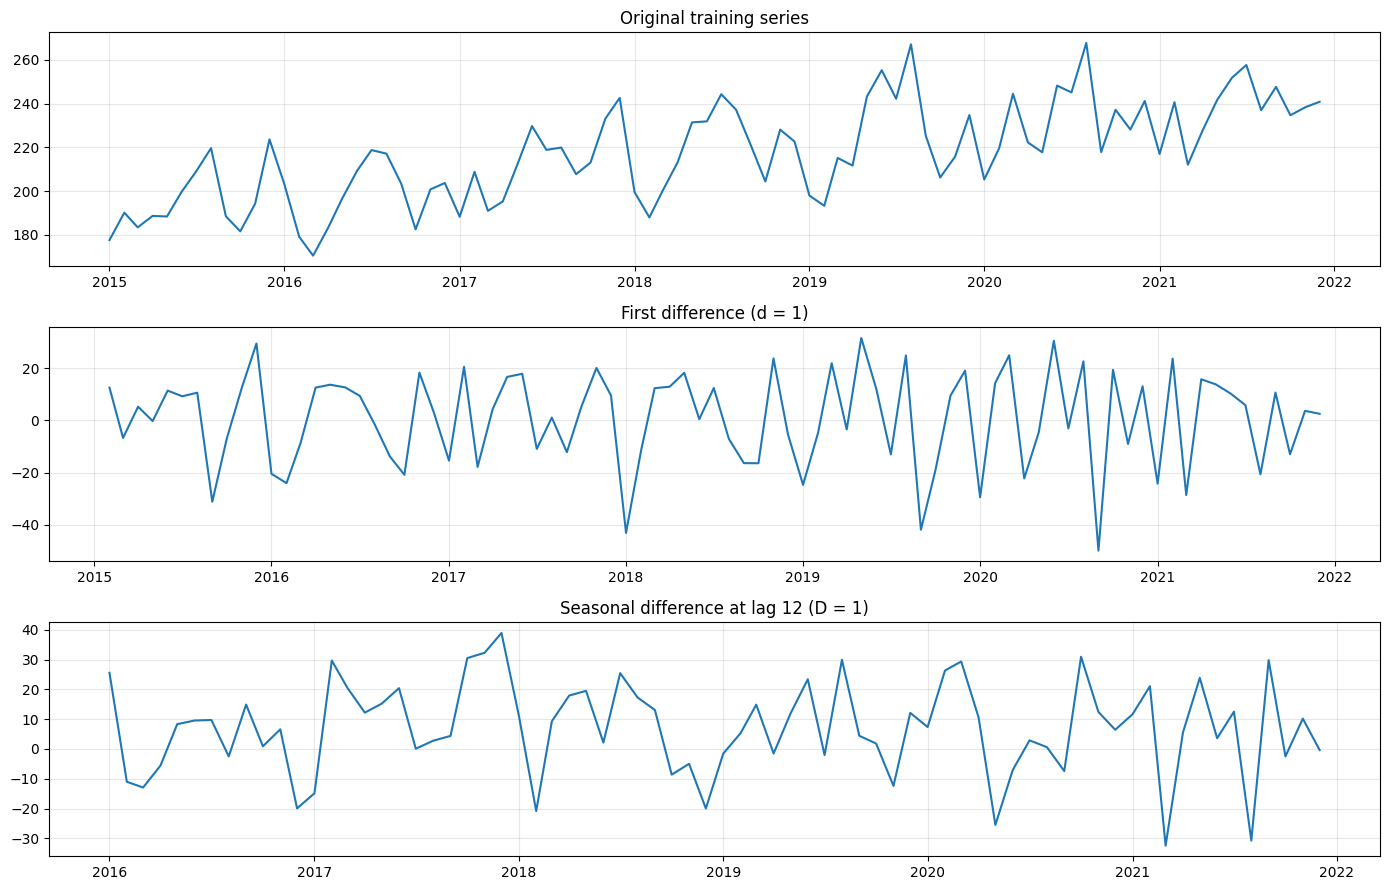

In [8]:
# Visualize first and seasonal differences for learning
first_diff = y_train.diff()
seasonal_diff = y_train.diff(12)

fig, axes = plt.subplots(3, 1, figsize=(14, 9))
axes[0].plot(y_train)
axes[0].set_title("Original training series")
axes[1].plot(first_diff)
axes[1].set_title("First difference (d = 1)")
axes[2].plot(seasonal_diff)
axes[2].set_title("Seasonal difference at lag 12 (D = 1)")
for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. ACF and PACF

ACF (autocorrelation function) shows correlation between a series and its lagged values. PACF (partial autocorrelation function) estimates the relationship at a lag after accounting for shorter lags.

They can help identify plausible AR and MA orders. Seasonal spikes around lag 12, 24, and so on may indicate annual seasonality. These plots are guides, not automatic order-selection rules. Inspect differenced data when choosing orders for a differenced model.

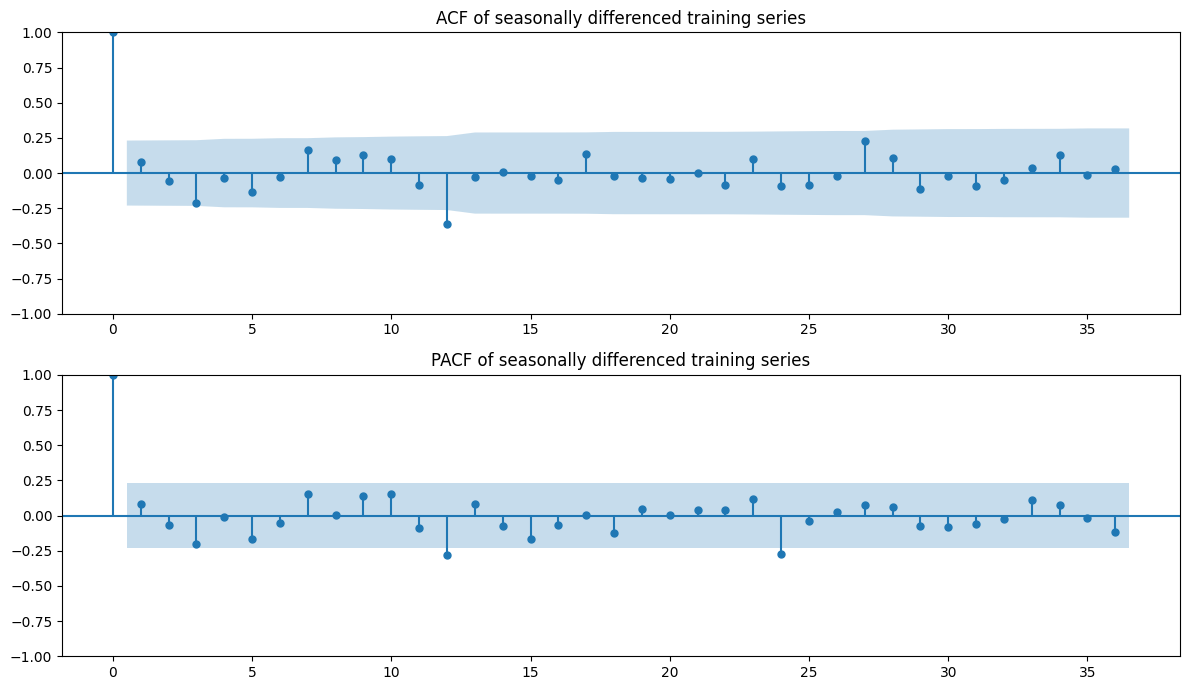

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
plot_acf(seasonal_diff.dropna(), lags=36, ax=axes[0])
plot_pacf(seasonal_diff.dropna(), lags=36, ax=axes[1], method="ywm")
axes[0].set_title("ACF of seasonally differenced training series")
axes[1].set_title("PACF of seasonally differenced training series")
plt.tight_layout()
plt.show()

## 7. Fit a SARIMA model

We begin with an illustrative specification:

`SARIMA(1, 1, 1) × (1, 1, 1, 12)`

This means:
- One non-seasonal AR term.
- One non-seasonal difference.
- One non-seasonal MA term.
- One seasonal AR term.
- One seasonal difference.
- One seasonal MA term.
- A 12-month seasonal period.

This is a starting candidate, not a universally optimal order. In a real project, compare a small set of sensible candidates using validation performance and information criteria, then inspect residuals.

In [10]:
sarima_order = (1, 1, 1)
seasonal_order = (1, 1, 1, 12)

sarima_model = SARIMAX(
    y_train,
    order=sarima_order,
    seasonal_order=seasonal_order,
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_result = sarima_model.fit(disp=False)
print(sarima_result.summary())

/Users/ashaythamankar/Library/CloudStorage/OneDrive-BlueYonder/Ashay Practice/BY Learnings/TimeSeries_Models/time_series_models/venv/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Users/ashaythamankar/Library/CloudStorage/OneDrive-BlueYonder/Ashay Practice/BY Learnings/TimeSeries_Models/time_series_models/venv/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                             demand   No. Observations:                   84
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -227.921
Date:                            Thu, 26 Nov 2026   AIC                            465.841
Time:                                    10:22:57   BIC                            476.056
Sample:                                01-01-2015   HQIC                           469.811
                                     - 12-01-2021                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1135      0.179      0.633      0.527      -0.238       0.465
ma.L1         -1.0000    980.490   

/Users/ashaythamankar/Library/CloudStorage/OneDrive-BlueYonder/Ashay Practice/BY Learnings/TimeSeries_Models/time_series_models/venv/lib/python3.10/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


## 8. Validate SARIMA

Forecast exactly the validation horizon. We use the validation set only to assess model performance and compare models; it is not used to fit this initial model.

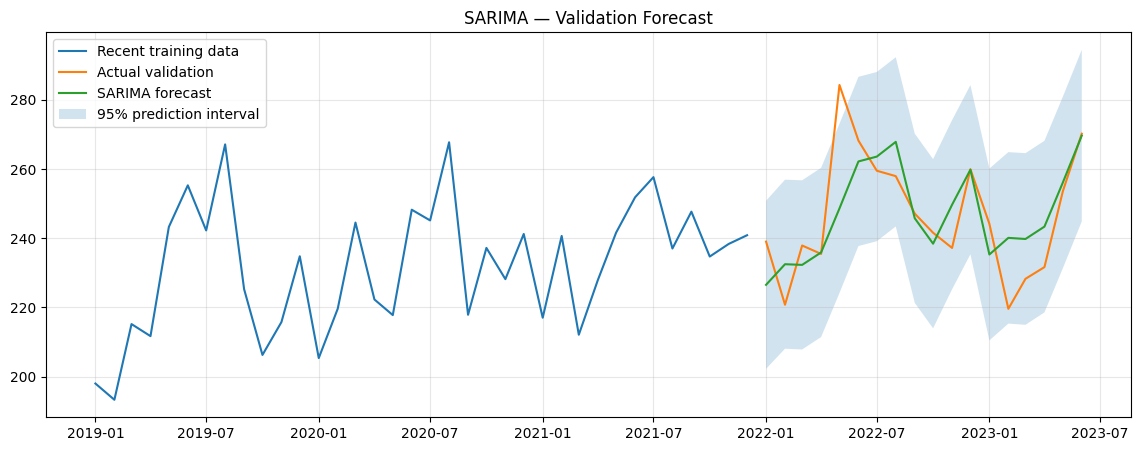

In [11]:
sarima_val_forecast_obj = sarima_result.get_forecast(steps=len(validation))
sarima_val_pred = sarima_val_forecast_obj.predicted_mean
sarima_val_ci = sarima_val_forecast_obj.conf_int()

sarima_val_pred.index = validation.index
sarima_val_ci.index = validation.index

plt.figure(figsize=(14, 5))
plt.plot(y_train.tail(36), label="Recent training data")
plt.plot(y_val, label="Actual validation")
plt.plot(sarima_val_pred, label="SARIMA forecast")
plt.fill_between(
    sarima_val_ci.index,
    sarima_val_ci.iloc[:, 0],
    sarima_val_ci.iloc[:, 1],
    alpha=0.2,
    label="95% prediction interval"
)
plt.title("SARIMA — Validation Forecast")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 9. Evaluation metrics

We use:
- **MAE**: average absolute forecast error, in the original demand units.
- **RMSE**: penalizes larger errors more heavily.
- **WMAPE**: total absolute error divided by total absolute actual demand.
- **Bias**: average forecast minus actual; positive means over-forecasting.

WMAPE is defined here as `sum(|forecast - actual|) / sum(|actual|)`. For a series whose actual values can be negative or whose denominator is zero, choose a metric definition appropriate to the use case.

In [12]:
def forecast_metrics(actual, predicted):
    actual = pd.Series(actual).astype(float)
    predicted = pd.Series(predicted, index=actual.index).astype(float)
    errors = predicted - actual
    denominator = np.abs(actual).sum()

    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "WMAPE": np.abs(errors).sum() / denominator if denominator != 0 else np.nan,
        "Bias (Forecast - Actual)": errors.mean()
    }

sarima_val_metrics = forecast_metrics(y_val, sarima_val_pred)
pd.Series(sarima_val_metrics, name="SARIMA validation")

MAE                          8.821986
RMSE                        12.234159
WMAPE                        0.035792
Bias (Forecast - Actual)     0.613554
Name: SARIMA validation, dtype: float64

## 10. Fit a SARIMAX model with exogenous variables

SARIMAX uses the same seasonal ARIMA structure but adds a regression component:

`y_t = β' x_t + u_t`

where:
- `x_t` is a vector of external predictors (exogenous variables).
- `β` contains their estimated coefficients.
- `u_t` follows a seasonal ARIMA process.

For this example, we use:
- `promotion`
- `price_index`
- `temperature`

The model can learn how these variables relate to demand while the SARIMA error process captures temporal dependence that remains after accounting for them.

**Critical forecasting requirement:** Exogenous variables must be available for every period being forecast. Historical values alone are not enough. For future forecasting, use known plans (e.g. promotion calendar), contractual values, or forecasts of the regressors. Do not accidentally use future realised values that would not have been available at forecast time.

In [13]:
exog_cols = ["promotion", "price_index", "temperature"]

X_train = train[exog_cols]
X_val = validation[exog_cols]
X_test = test[exog_cols]

sarimax_model = SARIMAX(
    y_train,
    exog=X_train,
    order=sarima_order,
    seasonal_order=seasonal_order,
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarimax_result = sarimax_model.fit(disp=False)
print(sarimax_result.summary())

/Users/ashaythamankar/Library/CloudStorage/OneDrive-BlueYonder/Ashay Practice/BY Learnings/TimeSeries_Models/time_series_models/venv/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Users/ashaythamankar/Library/CloudStorage/OneDrive-BlueYonder/Ashay Practice/BY Learnings/TimeSeries_Models/time_series_models/venv/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                             demand   No. Observations:                   84
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -199.650
Date:                            Thu, 26 Nov 2026   AIC                            415.300
Time:                                    10:23:01   BIC                            431.644
Sample:                                01-01-2015   HQIC                           421.652
                                     - 12-01-2021                                         
Covariance Type:                              opg                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
promotion      22.0640      2.485      8.880      0.000      17.194      26.934
price_index    -1.2954      0.57

## 11. Validate SARIMAX

The validation regressors are passed to `get_forecast`. Their rows must align with the forecast horizon and be in the same column order used during model fitting.

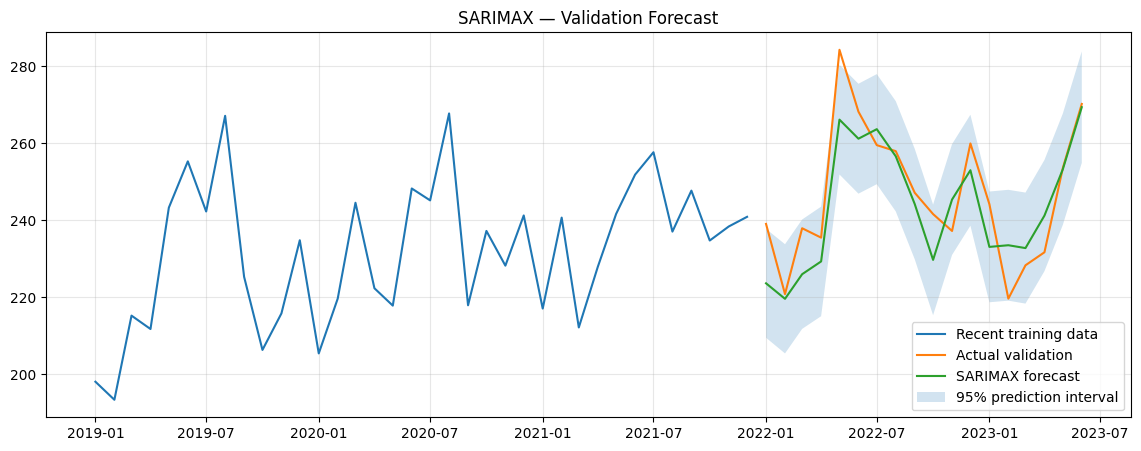

In [14]:
sarimax_val_forecast_obj = sarimax_result.get_forecast(
    steps=len(validation),
    exog=X_val
)
sarimax_val_pred = sarimax_val_forecast_obj.predicted_mean
sarimax_val_ci = sarimax_val_forecast_obj.conf_int()

sarimax_val_pred.index = validation.index
sarimax_val_ci.index = validation.index

plt.figure(figsize=(14, 5))
plt.plot(y_train.tail(36), label="Recent training data")
plt.plot(y_val, label="Actual validation")
plt.plot(sarimax_val_pred, label="SARIMAX forecast")
plt.fill_between(
    sarimax_val_ci.index,
    sarimax_val_ci.iloc[:, 0],
    sarimax_val_ci.iloc[:, 1],
    alpha=0.2,
    label="95% prediction interval"
)
plt.title("SARIMAX — Validation Forecast")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [15]:
comparison = pd.DataFrame({
    "SARIMA": forecast_metrics(y_val, sarima_val_pred),
    "SARIMAX": forecast_metrics(y_val, sarimax_val_pred)
}).T

comparison

,MAE,RMSE,WMAPE,Bias (Forecast - Actual)
SARIMA,8.821986,12.234159,0.035792,0.613554
SARIMAX,7.536339,9.170694,0.030576,-3.065653


### Interpreting the comparison

Do not assume SARIMAX must outperform SARIMA. External variables help only when they contain useful information, are measured reliably, and are available at forecast time. Too many weak or highly correlated regressors can make the model unstable or reduce out-of-sample accuracy.

Choose the model using validation performance and business requirements, not training fit alone.

## 12. Optional: compare a few candidate seasonal orders

Order selection is a modelling exercise. This small example compares a few candidates using validation WMAPE and AIC. Keep the search space compact and reasonable; exhaustive searches can be expensive, especially with long seasonal periods.

In [16]:
candidate_orders = [
    ((1, 1, 1), (1, 1, 1, 12)),
    ((1, 1, 0), (1, 1, 0, 12)),
    ((0, 1, 1), (0, 1, 1, 12)),
]

candidate_rows = []

for order, seasonal in candidate_orders:
    try:
        fitted = SARIMAX(
            y_train,
            order=order,
            seasonal_order=seasonal,
            trend="n",
            enforce_stationarity=False,
            enforce_invertibility=False
        ).fit(disp=False)

        pred = fitted.get_forecast(steps=len(validation)).predicted_mean
        pred.index = validation.index
        metrics = forecast_metrics(y_val, pred)

        candidate_rows.append({
            "order": order,
            "seasonal_order": seasonal,
            "AIC": fitted.aic,
            **metrics
        })
    except Exception as exc:
        print(f"Could not fit {order} x {seasonal}: {exc}")

candidate_results = pd.DataFrame(candidate_rows).sort_values("WMAPE")
candidate_results

/Users/ashaythamankar/Library/CloudStorage/OneDrive-BlueYonder/Ashay Practice/BY Learnings/TimeSeries_Models/time_series_models/venv/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Users/ashaythamankar/Library/CloudStorage/OneDrive-BlueYonder/Ashay Practice/BY Learnings/TimeSeries_Models/time_series_models/venv/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Users/ashaythamankar/Library/CloudStorage/OneDrive-BlueYonder/Ashay Practice/BY Learnings/TimeSeries_Models/time_series_models/venv/lib/python3.10/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/ashaythamankar/Library/

,order,seasonal_order,AIC,MAE,RMSE,WMAPE,Bias (Forecast - Actual)
2,"(0, 1, 1)","(0, 1, 1, 12)",462.526966,8.746413,12.135875,0.035485,0.193303
0,"(1, 1, 1)","(1, 1, 1, 12)",465.841094,8.821986,12.234159,0.035792,0.613554
1,"(1, 1, 0)","(1, 1, 0, 12)",500.689814,10.686833,15.526285,0.043358,-4.609741


## 13. Residual diagnostics

Residuals are the differences between observed values and fitted values. A good model should leave residuals that are approximately:
- centred around zero,
- free from substantial remaining autocorrelation,
- reasonably stable in variance.

The Ljung-Box test checks whether a group of autocorrelations is jointly different from zero. A small p-value suggests remaining autocorrelation. It is one diagnostic, not proof that a model is good or bad.

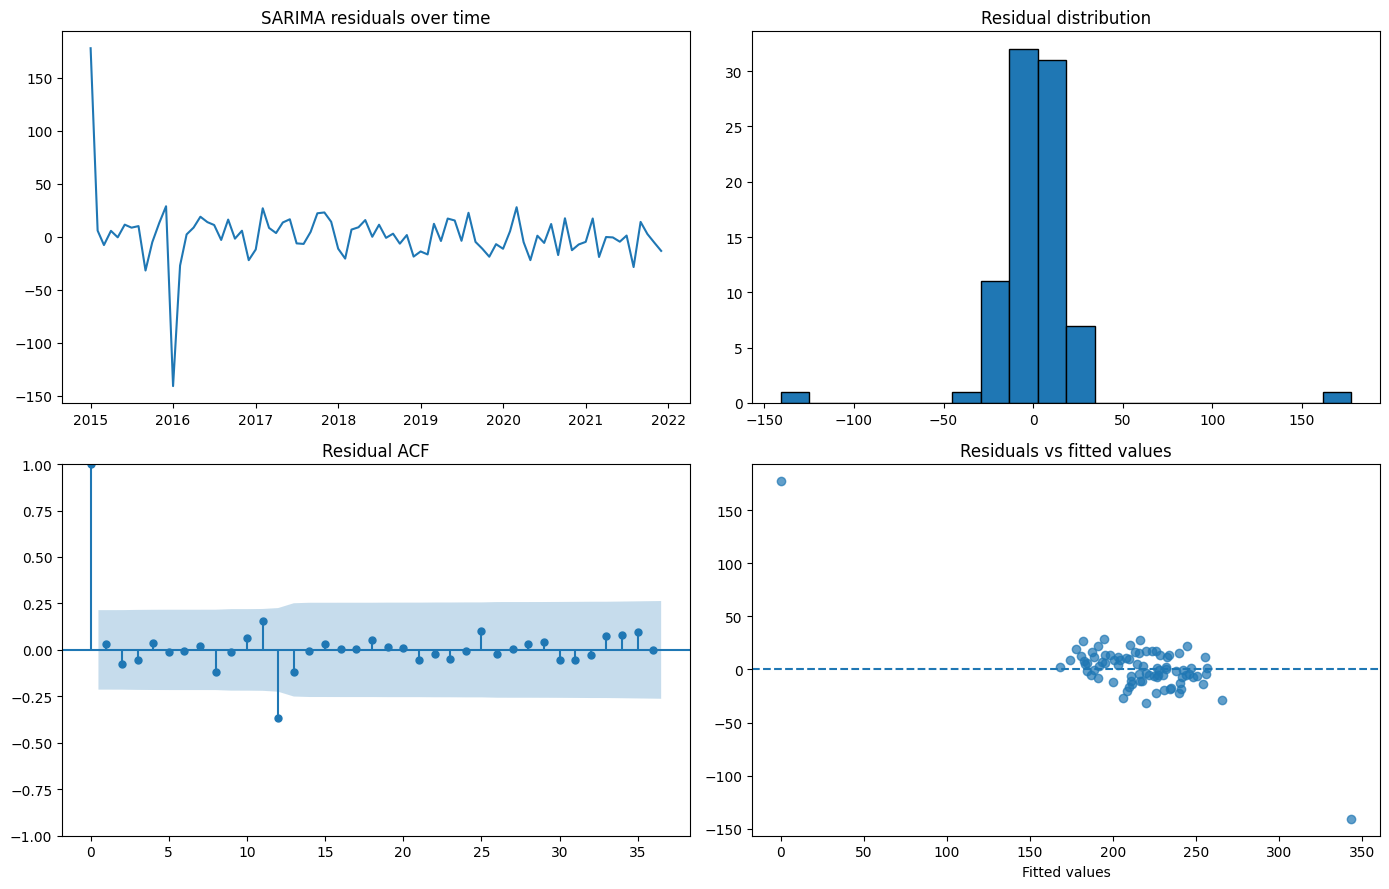

,lb_stat,lb_pvalue
12,18.687225,0.096361
24,21.358906,0.617473


In [17]:
residuals = sarima_result.resid.dropna()

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0, 0].plot(residuals)
axes[0, 0].set_title("SARIMA residuals over time")
axes[0, 1].hist(residuals, bins=20, edgecolor="black")
axes[0, 1].set_title("Residual distribution")
plot_acf(residuals, lags=36, ax=axes[1, 0])
axes[1, 0].set_title("Residual ACF")
axes[1, 1].scatter(sarima_result.fittedvalues, residuals, alpha=0.7)
axes[1, 1].axhline(0, linestyle="--")
axes[1, 1].set_title("Residuals vs fitted values")
axes[1, 1].set_xlabel("Fitted values")
plt.tight_layout()
plt.show()

lb = acorr_ljungbox(residuals, lags=[12, 24], return_df=True)
lb

## 14. Final test evaluation

After selecting a model using validation data, refit it on **training + validation** data, then evaluate once on the untouched test set.

For a clean demonstration, this section evaluates both example specifications. In a real workflow, choose the winner from validation first, and report the test result for that selected model.

In [18]:
train_val = pd.concat([train, validation])
y_train_val = train_val["demand"]

sarima_final = SARIMAX(
    y_train_val,
    order=sarima_order,
    seasonal_order=seasonal_order,
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_test_obj = sarima_final.get_forecast(steps=len(test))
sarima_test_pred = sarima_test_obj.predicted_mean
sarima_test_pred.index = test.index

sarimax_final = SARIMAX(
    y_train_val,
    exog=train_val[exog_cols],
    order=sarima_order,
    seasonal_order=seasonal_order,
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarimax_test_obj = sarimax_final.get_forecast(
    steps=len(test),
    exog=test[exog_cols]
)
sarimax_test_pred = sarimax_test_obj.predicted_mean
sarimax_test_pred.index = test.index

test_comparison = pd.DataFrame({
    "SARIMA": forecast_metrics(y_test, sarima_test_pred),
    "SARIMAX": forecast_metrics(y_test, sarimax_test_pred)
}).T

test_comparison

/Users/ashaythamankar/Library/CloudStorage/OneDrive-BlueYonder/Ashay Practice/BY Learnings/TimeSeries_Models/time_series_models/venv/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Users/ashaythamankar/Library/CloudStorage/OneDrive-BlueYonder/Ashay Practice/BY Learnings/TimeSeries_Models/time_series_models/venv/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Users/ashaythamankar/Library/CloudStorage/OneDrive-BlueYonder/Ashay Practice/BY Learnings/TimeSeries_Models/time_series_models/venv/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Users/ashaythamankar/Lib

,MAE,RMSE,WMAPE,Bias (Forecast - Actual)
SARIMA,11.870559,14.931292,0.045225,-1.575356
SARIMAX,6.454615,7.960625,0.024591,3.023447


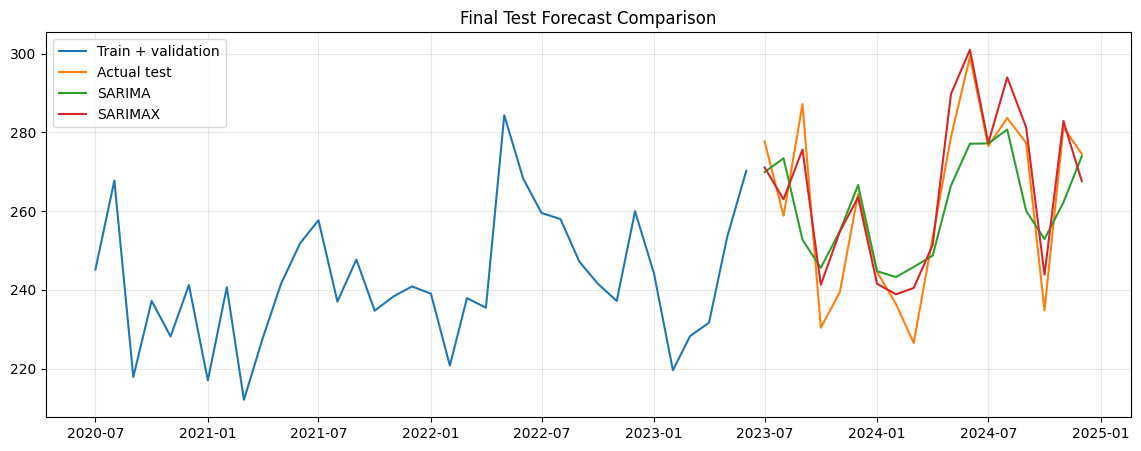

In [19]:
plt.figure(figsize=(14, 5))
plt.plot(y_train_val.tail(36), label="Train + validation")
plt.plot(y_test, label="Actual test")
plt.plot(sarima_test_pred, label="SARIMA")
plt.plot(sarimax_test_pred, label="SARIMAX")
plt.title("Final Test Forecast Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 15. Forecast the next 12 months

For SARIMA, no exogenous variables are required.

For SARIMAX, we must provide future values for every exogenous feature. Below we create an **illustrative scenario**:
- No promotions are assumed in the future.
- The price index is held at its last observed value.
- Temperature follows the average historical value for each calendar month.

These are assumptions, not known facts. In a real business forecast, replace them with approved promotion plans, pricing plans, and weather forecasts or scenarios.

In [20]:
future_dates = pd.date_range(
    start=df.index[-1] + pd.offsets.MonthBegin(1),
    periods=12,
    freq="MS"
)

sarima_future_obj = sarima_final.get_forecast(steps=12)
sarima_future = sarima_future_obj.predicted_mean
sarima_future_ci = sarima_future_obj.conf_int()
sarima_future.index = future_dates
sarima_future_ci.index = future_dates

# Create future exogenous-variable scenario
future_exog = pd.DataFrame(index=future_dates)
future_exog["promotion"] = 0
future_exog["price_index"] = train_val["price_index"].iloc[-1]

temperature_by_month = df.groupby(df.index.month)["temperature"].mean()
future_exog["temperature"] = [temperature_by_month[d.month] for d in future_dates]

sarimax_future_obj = sarimax_final.get_forecast(steps=12, exog=future_exog[exog_cols])
sarimax_future = sarimax_future_obj.predicted_mean
sarimax_future_ci = sarimax_future_obj.conf_int()
sarimax_future.index = future_dates
sarimax_future_ci.index = future_dates

future_forecasts = pd.DataFrame({
    "SARIMA_forecast": sarima_future,
    "SARIMA_lower_95": sarima_future_ci.iloc[:, 0],
    "SARIMA_upper_95": sarima_future_ci.iloc[:, 1],
    "SARIMAX_forecast": sarimax_future,
    "SARIMAX_lower_95": sarimax_future_ci.iloc[:, 0],
    "SARIMAX_upper_95": sarimax_future_ci.iloc[:, 1],
})

future_forecasts.round(2)

,SARIMA_forecast,SARIMA_lower_95,SARIMA_upper_95,SARIMAX_forecast,SARIMAX_lower_95,SARIMAX_upper_95
2025-01-01,269.92,246.07,293.76,268.67,253.88,283.46
2025-02-01,273.41,249.38,297.44,263.36,248.54,278.18
2025-03-01,252.73,228.69,276.76,252.98,238.16,267.81
2025-04-01,245.59,221.55,269.63,246.95,232.13,261.78
2025-05-01,254.89,230.85,278.93,261.72,246.90,276.54
2025-06-01,266.61,242.58,290.65,269.19,254.36,284.02
2025-07-01,244.74,220.71,268.78,249.35,234.57,264.13
2025-08-01,243.26,219.28,267.25,244.81,230.03,259.59
2025-09-01,245.83,221.83,269.82,245.41,230.63,260.19
2025-10-01,248.71,224.72,272.70,252.27,237.49,267.05


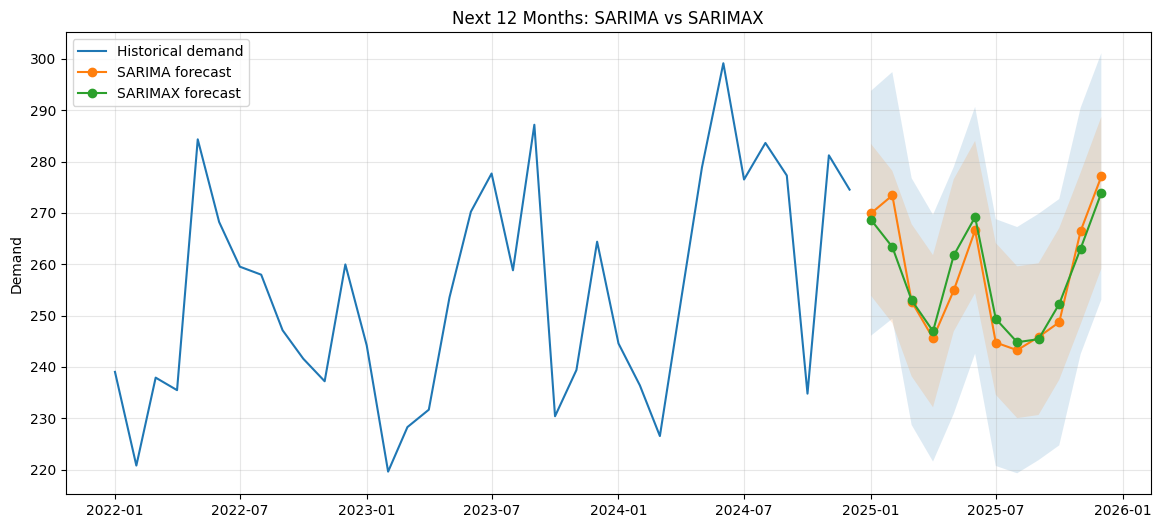

In [21]:
plt.figure(figsize=(14, 6))
plt.plot(df["demand"].tail(36), label="Historical demand")
plt.plot(sarima_future, marker="o", label="SARIMA forecast")
plt.plot(sarimax_future, marker="o", label="SARIMAX forecast")

plt.fill_between(
    sarima_future_ci.index,
    sarima_future_ci.iloc[:, 0],
    sarima_future_ci.iloc[:, 1],
    alpha=0.15
)
plt.fill_between(
    sarimax_future_ci.index,
    sarimax_future_ci.iloc[:, 0],
    sarimax_future_ci.iloc[:, 1],
    alpha=0.15
)

plt.title("Next 12 Months: SARIMA vs SARIMAX")
plt.ylabel("Demand")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 16. SARIMA vs SARIMAX — key differences

| Aspect | SARIMA | SARIMAX |
|---|---|---|
| Seasonal patterns | Yes | Yes |
| Non-seasonal ARIMA structure | Yes | Yes |
| External regressors | No | Yes |
| Future input requirement | Historical target | Historical target + future exogenous values |
| Example use | Demand with stable annual seasonality | Demand affected by promotions, price, holidays, weather |

In `statsmodels`, SARIMAX is the general state-space implementation. Fitting it without `exog` gives a seasonal ARIMA-type model; with `exog`, it becomes a regression with seasonal ARIMA errors. This is why the same `SARIMAX` class is used in both sections.

## 17. Practical considerations for supply-chain forecasting

### When SARIMA may be useful
- Demand has a reasonably stable seasonal pattern.
- There is sufficient historical data to estimate seasonal behaviour.
- No reliable external drivers are available.
- A statistical baseline is needed for comparison.

### When SARIMAX may be useful
- Promotions materially affect demand.
- Price changes influence sales.
- Holidays, weather, or calendar effects are measurable.
- External inputs are available for the full forecast horizon.

### Important cautions
1. **Forecast horizon:** Seasonal models need enough history to learn seasonal behaviour. A few seasonal cycles may be insufficient.
2. **Multiple seasonalities:** Standard SARIMA is best suited to a single seasonal period. Daily data may have both weekly and annual seasonality; consider methods designed for multiple seasonal patterns.
3. **Interventions and structural breaks:** New product launches, assortment changes, supply constraints, and market disruptions can invalidate historical relationships.
4. **Exogenous leakage:** Never train/evaluate with future realised regressors if those values would not have been known when the forecast was made.
5. **Regressor forecasts:** If future price or weather is itself forecast, its uncertainty is generally not fully represented by the SARIMAX prediction interval.
6. **Intermittent demand:** Standard SARIMA is often not ideal for highly intermittent, zero-heavy item-level demand. Croston-family methods or aggregation may be more suitable.
7. **Hierarchical demand:** Evaluate at the level where decisions are made and consider reconciliation when forecasts must add up across product/location hierarchies.

## 18. Common mistakes

- Using `s=12` for every dataset rather than matching the true seasonal cycle.
- Randomly shuffling observations before splitting.
- Selecting orders based only on AIC without checking out-of-sample accuracy.
- Ignoring residual autocorrelation.
- Supplying exogenous variables in a different order or with misaligned dates.
- Using future actual promotions/prices/weather in backtesting when they were not known at forecast origin.
- Assuming a more complex SARIMAX model always beats SARIMA.
- Treating prediction intervals as including uncertainty in future external-variable forecasts.

## 19. Key takeaway

**SARIMA models seasonality through seasonal autoregressive, differencing, and moving-average terms. SARIMAX adds external explanatory variables to that seasonal time-series structure.**

For demand forecasting, SARIMA is a useful seasonal statistical baseline. SARIMAX becomes valuable when drivers such as promotions, price, holidays, and weather provide reliable additional information—and when those drivers are available for the future forecast horizon.

### References
- [Statsmodels SARIMAX documentation](https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html)
- [Statsmodels forecasting example](https://www.statsmodels.org/stable/examples/notebooks/generated/statespace_sarimax_stata.html)
- [Forecasting: Principles and Practice — Seasonal ARIMA](https://otexts.com/fpp3/seasonal-arima.html)